# Diffusion coefficients from MSD

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import mdtraj

ATTENTION: Make sure the trajectory was obtained with `enforcePeriodicBox=False` in the `DCDReporter`, otherwise coordinates will be wrapped

In [2]:
trj = mdtraj.load('traj.dcd', top='config-p.pdb')
trj

dcdplugin) detected standard 32-bit DCD file of native endianness
dcdplugin) CHARMM format DCD file (also NAMD 2.1 and later)


<mdtraj.Trajectory with 2000 frames, 17100 atoms, 600 residues, and unitcells at 0x10b18d6d0>

In [3]:
cat = trj.topology.select("resname c2c and not (name =~ 'D.*')")
cat, len(cat)

(array([   0,    2,    4, ..., 8097, 8098, 8099], shape=(5700,)), 5700)

In [4]:
trj.xyz[0][0]

array([-0.15535346,  4.5436845 ,  0.2684228 ], dtype=float32)

In [7]:
ani = trj.topology.select("resname tf2 and not (name =~ 'D.*')")
len(ani)

4500

In [8]:
rmsd_cat = mdtraj.rmsd(trj, trj, atom_indices=cat)

In [9]:
rmsd_ani = mdtraj.rmsd(trj, trj, atom_indices=ani)

In [10]:
msd_cat = rmsd_cat**2
msd_ani = rmsd_ani**2

In [11]:
t = np.linspace(1, 5000, 2000)

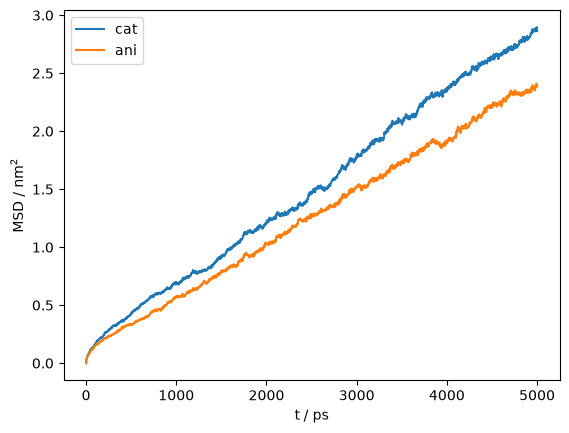

In [12]:
plt.plot(t, msd_cat, label='cat')
plt.plot(t, msd_ani, label='ani')
plt.xlabel('t / ps')
plt.ylabel('MSD / nm$^2$')
plt.legend()
plt.show()

In [13]:
np.savetxt('msd.out', np.column_stack((t, msd_cat, msd_ani)))

In [13]:
(Dc, bc) = np.polyfit(t[300:], msd_cat[300:], 1)

In [14]:
Dc/6/1e6

np.float64(9.389140205451107e-11)

In [15]:
(Da, ba) = np.polyfit(t[300:], msd_ani[300:], 1)

In [16]:
Da/6/1e6

np.float64(7.791029546560381e-11)

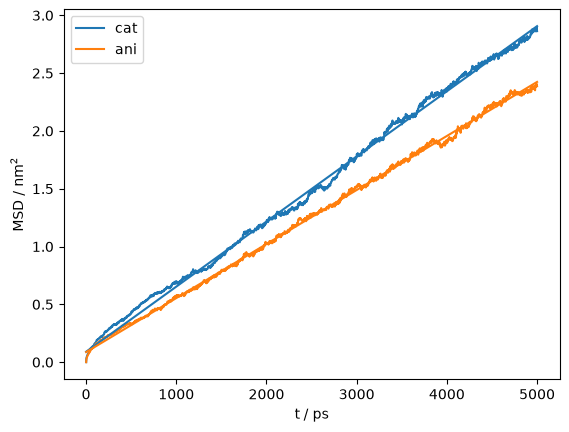

In [17]:
plt.plot(t, msd_cat, label='cat')
plt.plot(t, msd_ani, label='ani')
plt.plot(t, Dc*t + bc, 'C0-')
plt.plot(t, Da*t + ba, 'C1-')
plt.xlabel('t / ps')
plt.ylabel('MSD / nm$^2$')
plt.legend()
plt.show()